# HR Attrition Analytics

Saya memakai **data simulasi**, bukan catatan perusahaan. Saya meninjau keluaran pipeline dan memeriksa ulang penyebut turnover serta pemisahan waktu evaluasi.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root/'src'))
from hr_attrition.data import generate, turnover
from hr_attrition.model import split_cohorts
data = generate()
assert len(data) == 1500
data.head()

,employee_id,department,job_title,level,monthly_salary,last_raise_pct,last_raise_date,performance,distance_km,overtime_hours,engagement,age,gender,marital_status,last_promotion_date,manager_id,hire_date,exit_date,exit_reason,tenure_years
0,E0001,Teknologi,Staf,1,5827000.0,4.90,2022-08-26,2,12.8,8.5,2.84,24,Laki-laki,Belum menikah,2024-07-03,M16,2022-08-26,NaT,Aktif,2.351814
1,E0002,Operasional,Manajer,4,10861000.0,3.64,2022-07-12,4,14.7,26.0,3.51,38,Laki-laki,Menikah,NaT,M56,2022-07-12,NaT,Aktif,2.475017
2,E0003,Operasional,Staf,1,5109000.0,3.53,2022-09-26,4,5.5,21.1,4.56,34,Perempuan,Menikah,NaT,M43,2022-09-26,2022-12-01,Sukarela,0.180698
3,E0004,Teknologi,Supervisor,3,11791000.0,4.74,2022-02-22,3,22.0,0.5,4.85,31,Laki-laki,Menikah,NaT,M15,2022-02-22,NaT,Aktif,2.858316
4,E0005,SDM,Staf,1,7613000.0,2.24,2022-10-22,4,5.1,16.4,2.59,31,Laki-laki,Belum menikah,NaT,M41,2022-10-22,2023-05-05,Tidak sukarela,0.533881


## Headcount dan turnover

Saya memakai employee-days / jumlah hari kalender sebagai rerata headcount. Hari keluar tidak dihitung sebagai hari aktif. Turnover sukarela dan tidak sukarela memakai penyebut yang sama.

In [2]:
monthly, annual = turnover(data)
annual[annual.department == 'Semua']

,year,department,exits,voluntary,involuntary,average_headcount,turnover_rate,voluntary_rate,involuntary_rate,mean_exit_tenure
0,2022,Semua,123,103,20,717.339726,0.171467,0.143586,0.027881,0.317123
6,2023,Semua,244,201,43,1256.424658,0.194202,0.159978,0.034224,1.009201
12,2024,Semua,221,193,28,1013.950820,0.217959,0.190345,0.027615,1.954999


## Evaluasi 12 bulan

Saya memisahkan identitas karyawan sebelum membangun snapshot 2023 untuk training dan 2024 untuk testing. Variabel protected, tanggal keluar, alasan keluar, serta tenure final dikeluarkan dari fitur keputusan.

In [3]:
train, test = split_cohorts(data)
assert set(train.employee_id).isdisjoint(test.employee_id)
metrics = json.loads((root/'reports/metrics.json').read_text())
pd.DataFrame(metrics['models']).T

,validation_ap,auc,average_precision,brier,prevalence,confusion_matrix
Logistic regression,0.29304,0.691506,0.472009,0.160853,0.233533,"[[248, 8], [66, 12]]"
Random forest,0.295151,0.679487,0.472007,0.166187,0.233533,"[[256, 0], [78, 0]]"


## Survival dan asumsi

Saya memperlakukan semua exit sebagai event dan akhir 2024 sebagai censoring administratif. Cox memerlukan proportional hazards. Saya melaporkan tes Schoenfeld residual dengan transformasi rank dan koreksi Bonferroni.

In [4]:
pd.read_csv(root/'reports/cox_ph_diagnostics.csv')

,Unnamed: 0,test_statistic,p,-log2(p),bonferroni_p
0,department_Operasional,1.140863,0.285470,1.808589,1.0
1,department_Penjualan,1.356295,0.244181,2.033980,1.0
2,department_SDM,1.218938,0.269569,1.891273,1.0
3,department_Teknologi,0.492995,0.482594,1.051118,1.0
4,distance_km,0.004072,0.949122,0.075335,1.0
5,engagement,0.000194,0.988890,0.016118,1.0
6,last_raise_pct,0.001363,0.970549,0.043127,1.0
7,level,0.026094,0.871670,0.198146,1.0
8,monthly_salary,0.017583,0.894509,0.160832,1.0
9,overtime_hours,1.178525,0.277657,1.848627,1.0


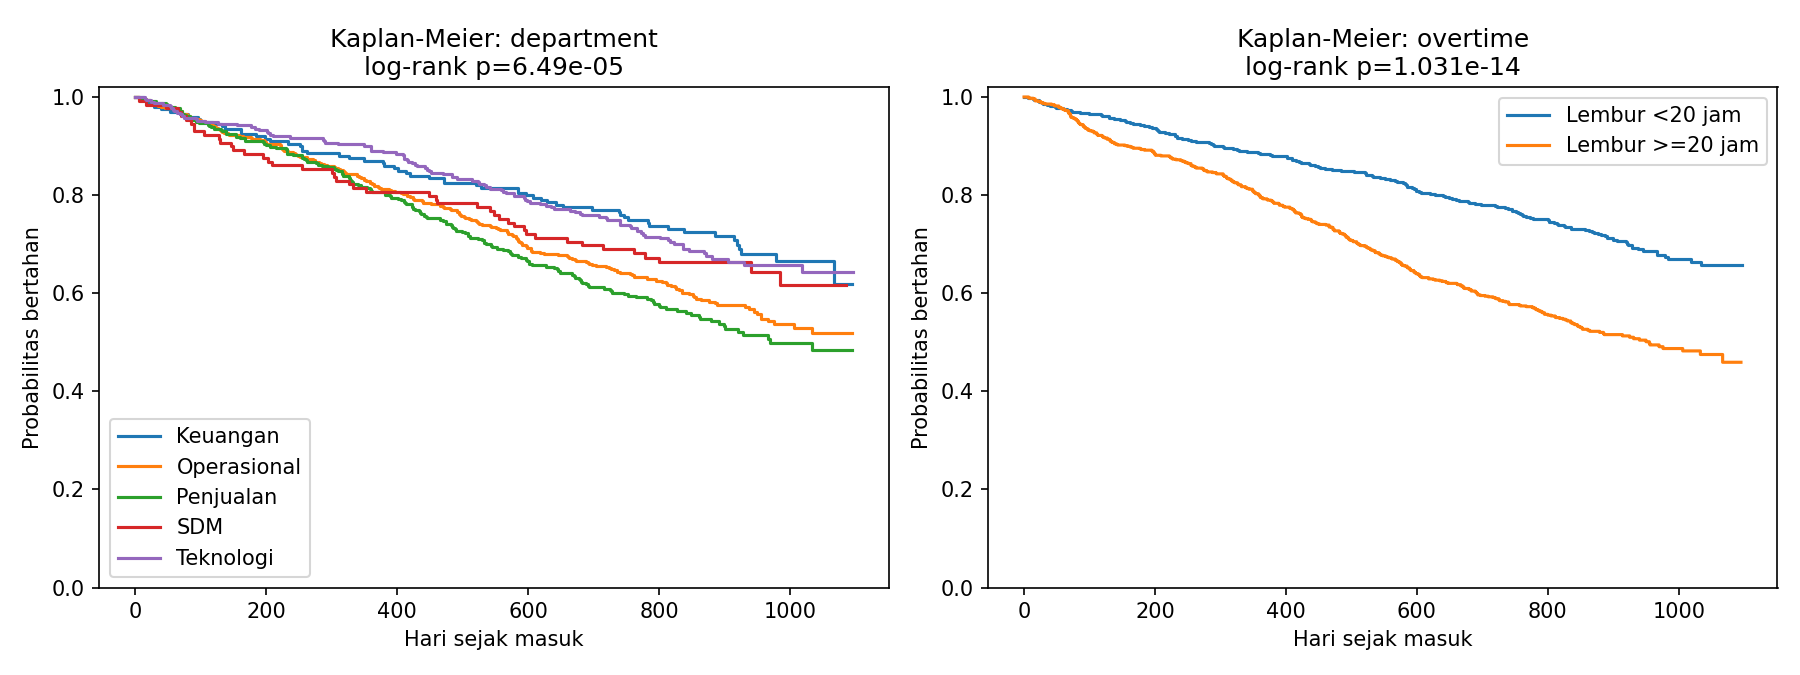

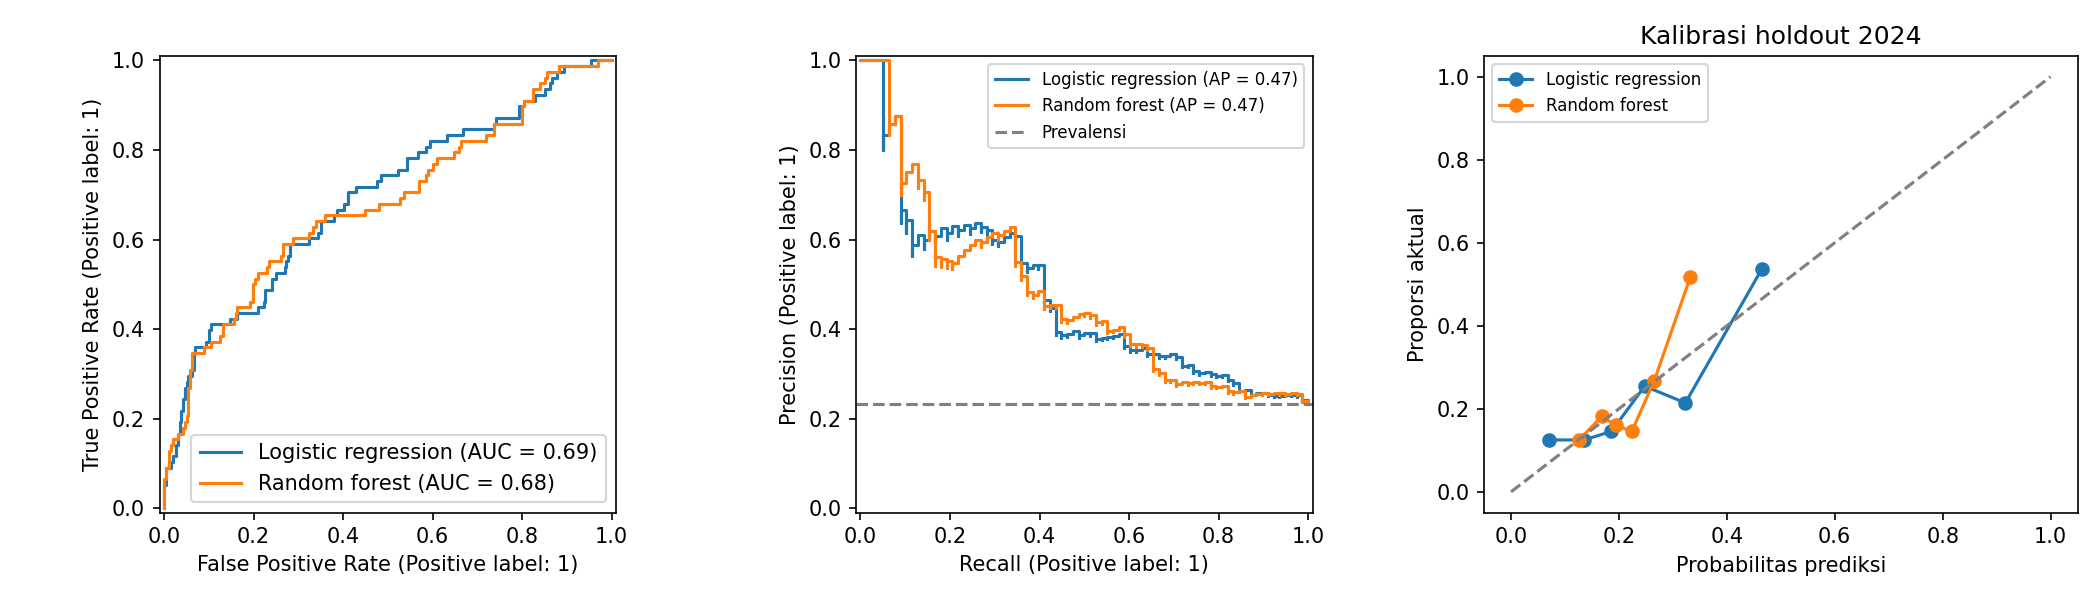

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/survival.png')))
display(Image(filename=str(root/'assets/evaluation.png')))

## Interpretasi dan batas

Saya memakai risiko untuk mendukung percakapan retensi sukarela. Perubahan probabilitas terhadap nilai acuan bukan efek kausal dan bukan alasan pemutusan kerja. Simulasi penghematan mengasumsikan exit berkurang 20%, bukan hasil intervensi yang sudah terbukti.